# Organising the Dataset

Before we can start downloading and preprocessing medical imaging data we need to first clean and process the dataset, reducing it to only sessions that meet our requirements. The requirements being:

1. Simplify clinical diagnoses into binary labels.
2. Find the most common MRI type and select sessions
3. For each MRI find a corresponding PET session that is within 6 months
4. Apply labeled diagnosis with historical diagnoses data

## Reading the data

The Oasis 3 dataset supplies a folder with data about the MRI and PET scans, as well as the subjects and diagnosis. This data is fragmented into multiple csv files and an MRI scan does not necessarily have a corresponding PET scan. Some entries contain errors or null values that need to be dropped or replaced.

In [ ]:
import os
import re
import pandas as pd
import numpy as np

data_path = "/home/kamran/projects/final-project/src/dataset/OASIS3_data_files/"

healthy_data = pd.read_csv(os.path.join(data_path, "CogNorm-Cognitively_Normal_Cohorts/OASIS3_unchanged_CDR_cognitively_healthy.csv"))
cdr_data = pd.read_csv(os.path.join(data_path, "UDSb4-Form_B4__Global_Staging__CDR__Standard_and_Supplemental/OASIS3_UDSb4_cdr.csv"))
diag_data = pd.read_csv(os.path.join(data_path, "UDSd1-Form_D1__Clinician_Diagnosis___Cognitive_Status_and_Dementia/OASIS3_UDSd1_diagnoses.csv"))
mri_data = pd.read_csv(os.path.join(data_path, "MRI-json-MRI_json_information/OASIS3_MR_json.csv"))
pet_data = pd.read_csv(os.path.join(data_path, "PET-json-PET_json_information/OASIS3_PET_json.csv"))
pup_data = pd.read_csv(os.path.join(data_path, "PUP-PUP_output/OASIS3_PUP.csv"))


str_cols = ['OASISID', 'OASIS_session_label', 'dx1', 'dx2', 'dx3', 'dx4', 'dx5']
cdr_data[str_cols] = cdr_data[str_cols].apply(lambda s: s.astype(str))

# Find all cognitively healthy participants
healthy_ids = [str(x) for x in healthy_data['OASIS3_id'].unique()]
cdr_data_healthy = cdr_data[cdr_data['CDRTOT'] == 0]
cdr_healthy_ids = [str(x) for x in cdr_data_healthy.OASISID.unique()]

print("Received Healthy Diagnoses:",len(cdr_healthy_ids))
print("Unchanged Healthy:", len(healthy_ids))
difference = set(cdr_healthy_ids).difference(set(healthy_ids))
print("Converted:", len(difference))

Received Healthy Diagnoses: 1076
Unchanged Healthy: 755
Converted: 321


We can see that of 1076 patients who received a cognitively healthy evaluation, only 755 remained cognitively healthy throughout the study, with 321 patients having received a higher CDR score and evaluation, indicating potential dementia. This data could be potentially useful for detecting earlier signs of dementia.

### Simplifying Categories

Here I am simplifying the diagnosis labels into two categories DEMENTED and NON-DEMENTED, any values that don't fall into these categories are discarded. Where values are missing, there is an attempt to reconstruct the correct value by comparing the patient ID to known healthy individuals, and finding an average diagnosis from the CDR data where multiple clinical diagnosis is available.

In [15]:
cdr_df = cdr_data.copy(deep=True)
cdr_df.replace({'.': None, np.nan: None}, inplace=True)

def convert(d):
    keywords = ['DAT',
                'AD dem',
                'Vascular dem',
                'Frontotemporal dem',
                'Active PSNP',
                'Dementia', 'DLBD',
                'Incipient demt',
                'Uncertain dementia']
    if re.match(f'^({"|".join(keywords)})', d, re.I):
        return 1
    elif re.match(f'^unc', d, re.I):
        return 0.5
    else:
        return 0


cdr_df['DEMENTED'] = None
print("Dementia:", cdr_df.shape[0])

for index, row in cdr_df.iterrows():
    if row['dx1'] == None:
        cdr_df.drop(index, inplace=True)
        continue
    
    d1 = convert(row['dx1'])

    sum = d1
    check = 1
    for i in range(2,6):
        dx = row[f'dx{i}']
        if dx == 'A':
            sum += d1
            check += 1
        elif dx != None:
            sum += convert(dx)
            check += 1

    avg = float(sum) / check
    cdr_df.at[index, 'DEMENTED'] = round(avg)

print("Dementia:", cdr_df.DEMENTED.value_counts())
cdr_df.to_csv("CDR_diagnosis.csv")


Dementia: 8626
Dementia: DEMENTED
0    7016
1    1567
Name: count, dtype: int64


### Label Correction

It is hard to tell when dementia is present, because of this a subject may have multiple positive scans succeeded by multiple negative scans. We use a 2N neighbour comparison algorithm to try and correct anamolies in the data. This should show good correlation to disease progression on the MRIs.

Dementia: DEMENTED
False    6976
1        1607
Name: count, dtype: int64


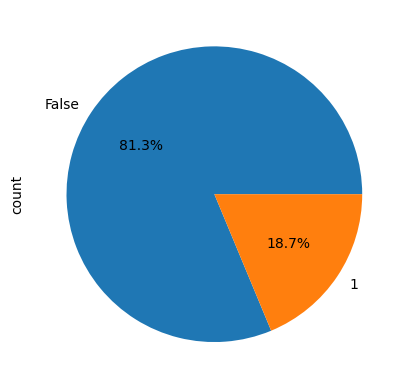

In [16]:
import matplotlib.pyplot as plt

cdr_df = cdr_df.sort_values(by=['OASISID', 'days_to_visit']).reset_index(drop=True)
current_subj = None
for index, row in cdr_df.iterrows():
    if current_subj != row['OASISID']:
        current_subj = row['OASISID']
        prec = (None, None) # i-2, i-1
        succ = (cdr_df.at[index + 1, 'DEMENTED'] if index + 1 < cdr_df.shape[0] and cdr_df.at[index + 1, 'OASISID'] == current_subj else None,
                cdr_df.at[index + 2, 'DEMENTED'] if index + 2 < cdr_df.shape[0] and cdr_df.at[index + 2, 'OASISID'] == current_subj else None)

    if row['DEMENTED'] == True:
        new = int(prec[1] or any(succ))
    else:
        new = int(any(prec) and any(succ)) or all(prec)
    cdr_df.at[index, 'DEMENTED'] = new

    prec = (prec[1], new) # i-1, i
    succ = (succ[1], cdr_df.at[index + 3, 'DEMENTED'] if index + 3 in cdr_df.index and cdr_df.at[index + 3, 'OASISID'] == current_subj else None)

print("Dementia:", cdr_df.DEMENTED.value_counts())
cdr_df['DEMENTED'].value_counts().plot.pie(autopct='%1.1f%%')
cdr_df.to_csv("diagnosis.csv")

### Combining the PUP (Pet Unified Pipeline) with Labels

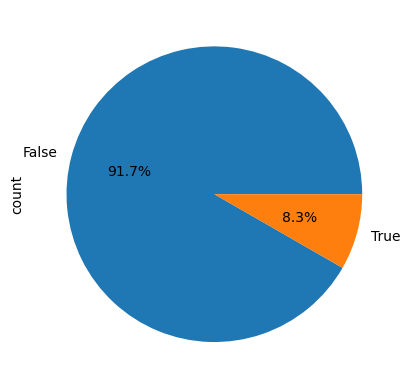

In [17]:
labeled_dataset = pup_data.copy()
labeled_dataset.drop(columns=['procType', 'model', 'FSId', 'mocoError', 'regError', 'Centil_fBP_TOT_CORTMEAN', 'Centil_fSUVR_TOT_CORTMEAN', 'Centil_fBP_rsf_TOT_CORTMEAN', 'Centil_fSUVR_rsf_TOT_CORTMEAN'], inplace=True)
labeled_dataset['label'] = None
for index, row in labeled_dataset.iterrows():
    subject = row['MRId'].split("_")[0]
    time = int(row['PUP_PUPTIMECOURSEDATA ID'].split('_')[-1][1:])
    rows_of_subject = cdr_df.loc[cdr_df['OASISID'] == row['MRId'].split("_")[0]][['days_to_visit', 'DEMENTED']]
    rows_of_subject['days_to_visit'] = rows_of_subject['days_to_visit'].apply(lambda x: abs(x - time))
    # print(rows_of_subject.groupby(by='days_to_visit', as_index=False).any().sort_values(by='days_to_visit'))
    try:
        labeled_dataset.at[index,'label'] = (rows_of_subject.groupby(by='days_to_visit', as_index=False)
                                                            .any()
                                                            .sort_values(by='days_to_visit')
                                                            .loc[0]['DEMENTED'])
    except KeyError:
        labeled_dataset.drop(index, inplace=True)

labeled_dataset['label'].value_counts().plot.pie(autopct='%1.1f%%')
labeled_dataset.to_csv('labeled_dataset_b4.csv')

Because it is very hard to diagnose early onset dementia, I will be using the first and last MRIs of patients who were initially tested as healthy and were subsequently diagnosed with dementia. For the patients that were healthy throughout the study, I shall only use the first MRI that was taken as that is the point were the brain is most likely to be free of abnormalities or undiagnosed dementia, this will also help avoid future bias where little variance is observed over time in healthy individuals causing overfitting.

### Reading associated PET scan